<a href="https://colab.research.google.com/github/renatobdo/doutorado/blob/main/02_normalizacao_cid_sim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Título e objetivo

# Normalização e enriquecimento dos códigos CID-10 do SIM

Este notebook realiza a normalização dos códigos CID-10 presentes nas causas
dos óbitos cuja causa básica foi dengue.

As principais etapas são:

1. Carregamento dos dados extraídos do SIM;
2. Seleção das colunas relacionadas às causas do óbito;
3. Transformação das colunas de causas para formato longitudinal;
4. Separação de múltiplos códigos registrados no mesmo campo;
5. Normalização dos códigos CID-10;
6. Associação dos códigos às descrições da CID-10;
7. Validação dos códigos não encontrados;
8. Geração e salvamento da base enriquecida.

O resultado deste notebook será utilizado nas análises de causas e condições
mencionadas nos óbitos por dengue.

2 - Importação das bibliotecas

In [ ]:
import os
import re
import numpy as np
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


3. Definição dos caminhos

In [ ]:
import os
import pandas as pd

BASE_DIR = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag"
)

CAMINHO_ENTRADA = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_reduzido.csv"
)

CAMINHO_CATEGORIAS = os.path.join(
    BASE_DIR,
    "data_docs",
    "CID10CSV",
    "CID-10-CATEGORIAS.CSV"
)

CAMINHO_SUBCATEGORIAS = os.path.join(
    BASE_DIR,
    "data_docs",
    "CID10CSV",
    "CID-10-SUBCATEGORIAS.CSV"
)

CAMINHO_SAIDA_CAUSAS = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_causas_cid10.csv"
)

CAMINHO_SAIDA_FREQUENCIAS = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_frequencia_cid10.csv"
)

4. Carregamento dos dados do notebook 01

In [ ]:
if not os.path.exists(CAMINHO_ENTRADA):
    raise FileNotFoundError(
        f"Arquivo de entrada não encontrado: {CAMINHO_ENTRADA}"
    )

df_sim = pd.read_csv(CAMINHO_ENTRADA)

print("Base carregada com sucesso.")
print(f"Registros: {len(df_sim):,}")
print(f"Colunas: {df_sim.shape[1]}")

Base carregada com sucesso.
Registros: 1,322
Colunas: 16


Confira as colunas:

In [ ]:
df_sim.columns.tolist()

['DTOBITO',
 'TIPOBITO',
 'IDADE',
 'SEXO',
 'RACACOR',
 'CODMUNRES',
 'CODMUNOCOR',
 'LOCOCOR',
 'CODESTAB',
 'ESTABDESCR',
 'CAUSABAS',
 'LINHAA',
 'LINHAB',
 'LINHAC',
 'LINHAD',
 'LINHAII']

5. Criação de um identificador para cada óbito.

O identificador deve ser criado antes de transformar as causas em linhas:

In [ ]:
df_sim = df_sim.reset_index(drop=True).copy()

if "ID_REGISTRO" not in df_sim.columns:
    df_sim.insert(
        0,
        "ID_REGISTRO",
        df_sim.index + 1
    )

Validação:

In [ ]:
assert df_sim["ID_REGISTRO"].is_unique
assert df_sim["ID_REGISTRO"].notna().all()

df_sim[["ID_REGISTRO", "CAUSABAS"]].head()

,ID_REGISTRO,CAUSABAS
0,1,A91
1,2,A91
2,3,A91
3,4,A91
4,5,A90


É importante deixar explícito que esse identificador é interno:

> `ID_REGISTRO` é um identificador criado para processamento no notebook.
> Ele não corresponde a um identificador oficial disponibilizado pelo SIM.

6. Seleção das colunas de causas

In [ ]:
COLUNAS_CAUSAS = [
    "CAUSABAS",
    "LINHAA",
    "LINHAB",
    "LINHAC",
    "LINHAD",
    "LINHAII"
]

Valide se todas estão disponíveis:

In [ ]:
colunas_ausentes = [
    coluna
    for coluna in COLUNAS_CAUSAS
    if coluna not in df_sim.columns
]

if colunas_ausentes:
    raise KeyError(
        f"Colunas de causas ausentes: {colunas_ausentes}"
    )

Você também pode registrar o papel dos campos:

In [ ]:
PAPEIS_CAUSAS = {
    "CAUSABAS": "Causa básica",
    "LINHAA": "Linha A da Parte I",
    "LINHAB": "Linha B da Parte I",
    "LINHAC": "Linha C da Parte I",
    "LINHAD": "Linha D da Parte I",
    "LINHAII": "Outras condições significativas — Parte II"
}

7. Transformação para formato longitudinal

No formato original, cada tipo de causa ocupa uma coluna. Para análise, é mais adequado criar uma linha para cada campo.
Essa transformação muda o foco de "um óbito com várias colunas de causas" para "várias ocorrências de causas ligadas a um mesmo óbito", o que simplifica a integração semântica, as consultas e as análises posteriores.

Transforma isso:
| ID_REGISTRO | CAUSABAS | CAUSABAS_O | LINHAA | LINHAB | LINHAC | LINHAD |
| ----------- | -------- | ---------- | ------ | ------ | ------ | ------ |
| 1           | A90      | A90        | J189   | E119   | I10    |        |
| 2           | A91      | A91        | J960   | A419   |        |        |

Cada coluna representa uma posição diferente da Declaração de Óbito:

CAUSABAS → causa básica
LINHAA → causa informada na linha A
LINHAB → linha B
LINHAC → linha C
LINHAD → linha D
etc.

O problema é que as causas estão distribuídas em diversas colunas.
Segue a transformação:
| ID_REGISTRO | CAMPO_CAUSA | VALOR_ORIGINAL |
| ----------- | ----------- | -------------- |
| 1           | CAUSABAS    | A90            |
| 1           | LINHAA      | J189           |
| 1           | LINHAB      | E119           |
| 1           | LINHAC      | I10            |
| 2           | CAUSABAS    | A91            |
| 2           | LINHAA      | J960           |
| 2           | LINHAB      | A419           |



In [ ]:
df_causas_long = df_sim.melt(
    id_vars=["ID_REGISTRO"],
    value_vars=COLUNAS_CAUSAS,
    var_name="CAMPO_CAUSA",
    value_name="VALOR_ORIGINAL"
)

Adicione a descrição do campo:

In [ ]:
df_causas_long["PAPEL_CAUSA"] = (
    df_causas_long["CAMPO_CAUSA"]
    .map(PAPEIS_CAUSAS)
)

Remova valores vazios:

In [ ]:
df_causas_long["VALOR_ORIGINAL"] = (
    df_causas_long["VALOR_ORIGINAL"]
    .astype("string")
    .str.strip()
)

df_causas_long = df_causas_long[
    df_causas_long["VALOR_ORIGINAL"].notna()
    &
    df_causas_long["VALOR_ORIGINAL"].ne("")
].copy()

Visualização:

In [ ]:
df_causas_long.head(20)

,ID_REGISTRO,CAMPO_CAUSA,VALOR_ORIGINAL,PAPEL_CAUSA
0,1,CAUSABAS,A91,Causa básica
1,2,CAUSABAS,A91,Causa básica
2,3,CAUSABAS,A91,Causa básica
3,4,CAUSABAS,A91,Causa básica
4,5,CAUSABAS,A90,Causa básica
5,6,CAUSABAS,A91,Causa básica
6,7,CAUSABAS,A90,Causa básica
7,8,CAUSABAS,A90,Causa básica
8,9,CAUSABAS,A91,Causa básica
9,10,CAUSABAS,A91,Causa básica


8. Separação automática dos códigos CID-10

Esta é uma das partes centrais do notebook.

Valores como:

*I10X*E149

devem gerar duas linhas:

I10X
E149

Use a expressão regular:

In [ ]:
PADRAO_CID = r"[A-Z][0-9]{2}[A-Z0-9]?"

Extração:

In [ ]:
df_causas_long["CODIGOS_EXTRAIDOS"] = (
    df_causas_long["VALOR_ORIGINAL"]
    .str.upper()
    .str.findall(PADRAO_CID)
)

Explosão da lista de códigos:

In [ ]:
df_causas_separadas = (
    df_causas_long
    .explode("CODIGOS_EXTRAIDOS")
    .rename(
        columns={
            "CODIGOS_EXTRAIDOS": "CODIGO_SIM"
        }
    )
    .dropna(subset=["CODIGO_SIM"])
    .copy()
)

Normalize:

In [ ]:
df_causas_separadas["CODIGO_SIM"] = (
    df_causas_separadas["CODIGO_SIM"]
    .astype("string")
    .str.upper()
    .str.strip()
    .str.replace(".", "", regex=False)
)

Exemplo de validação:

In [ ]:
df_causas_separadas[
    df_causas_separadas["VALOR_ORIGINAL"]
    .str.contains(r"\*.*\*", regex=True, na=False)
][
    [
        "ID_REGISTRO",
        "CAMPO_CAUSA",
        "VALOR_ORIGINAL",
        "CODIGO_SIM"
    ]
].head(20)

,ID_REGISTRO,CAMPO_CAUSA,VALOR_ORIGINAL,CODIGO_SIM
1391,70,LINHAA,*J159*Y95X,J159
1391,70,LINHAA,*J159*Y95X,Y95X
1426,105,LINHAA,*R571*R578,R571
1426,105,LINHAA,*R571*R578,R578
1458,137,LINHAA,*A419*J181,A419
1458,137,LINHAA,*A419*J181,J181
1508,187,LINHAA,*A419*J189,A419
1508,187,LINHAA,*A419*J189,J189
1566,245,LINHAA,*R570*I420,R570
1566,245,LINHAA,*R570*I420,I420


9. Criação das versões do código CID

Mantenha o código original extraído e crie códigos auxiliares:

Um exemplo completo

Suponha que o SIM contenha:

| CODIGO_SIM |
| ---------- |
| A920       |


Após essa etapa:

| CODIGO_SIM | CODIGO_CATEGORIA | CODIGO_SUBCATEGORIA |
| ---------- | ---------------- | ------------------- |
| A920       | A92              | A920                |



Depois você poderá fazer dois joins:

A92 → obtém a descrição da categoria.
A920 → obtém a descrição da subcategoria (quando existir).

Um resumo dos passos 9 ao 13

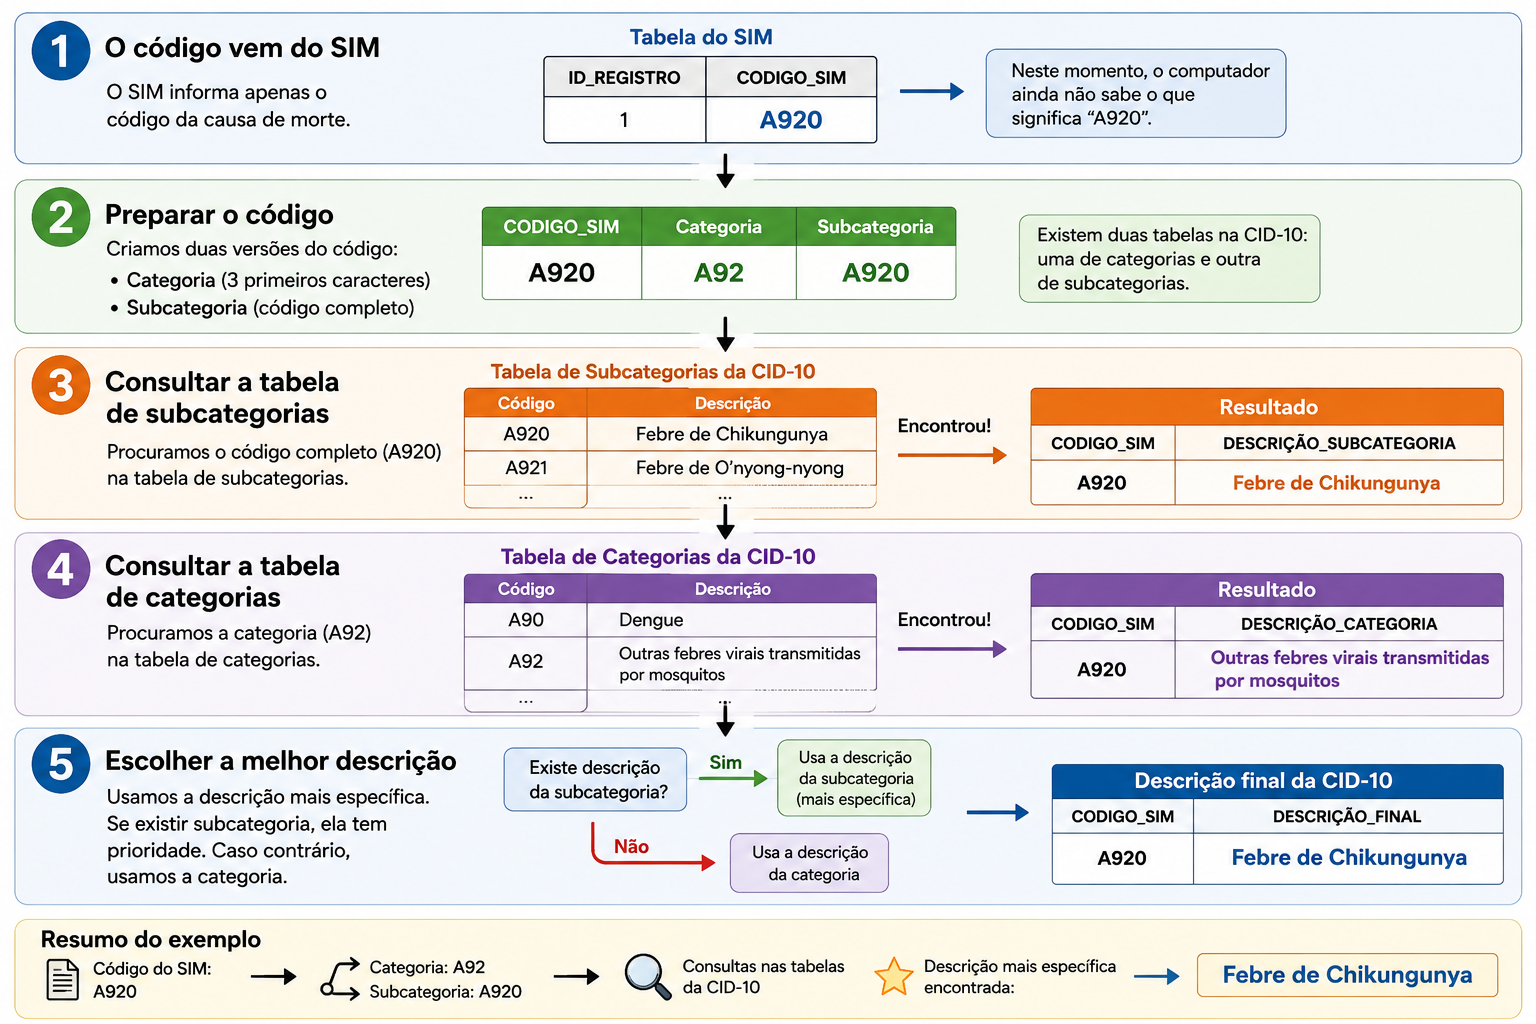

In [ ]:
df_causas_separadas["CODIGO_CATEGORIA"] = (
    df_causas_separadas["CODIGO_SIM"]
    .str[:3]
)

df_causas_separadas["CODIGO_SUBCATEGORIA"] = (
    df_causas_separadas["CODIGO_SIM"]
)

Exemplos:

| Código SIM | Categoria | Subcategoria |
| ---------- | --------- | ------------ |
| `A90X`     | `A90`     | `A90X`       |
| `A419`     | `A41`     | `A419`       |
| `R571`     | `R57`     | `R571`       |
| `I10X`     | `I10`     | `I10X`       |

Não recomendo remover o X diretamente, pois ele faz parte da codificação utilizada no arquivo do SIM. O código deve ser preservado para rastreabilidade

10. Carregamento da referência CID-10

Crie uma função resistente a diferenças de codificação e separador:

Se usarmos uma configuração errada, podem aparecer erros ou caracteres incorretos, como:

DoenÃ§as infecciosas

em vez de:

Doenças infecciosas

In [ ]:
def ler_csv_cid(caminho: str) -> pd.DataFrame:
    """Lê um arquivo CSV de referência da CID-10."""

    tentativas = [
        {"sep": ";", "encoding": "latin-1"},
        {"sep": ";", "encoding": "utf-8"},
        {"sep": ",", "encoding": "latin-1"},
        {"sep": ",", "encoding": "utf-8"}
    ]

    erros = []

    for parametros in tentativas:
        try:
            dataframe = pd.read_csv(
                caminho,
                dtype="string",
                **parametros
            )

            if dataframe.shape[1] > 1:
                print(
                    f"Arquivo lido com separador "
                    f"'{parametros['sep']}' e codificação "
                    f"'{parametros['encoding']}'."
                )
                return dataframe

        except Exception as erro:
            erros.append(str(erro))

    raise ValueError(
        f"Não foi possível ler o arquivo {caminho}. "
        f"Erros encontrados: {erros}"
    )

Carregue:

In [ ]:
df_categorias_raw = ler_csv_cid(
    CAMINHO_CATEGORIAS
)

df_subcategorias_raw = ler_csv_cid(
    CAMINHO_SUBCATEGORIAS
)

Arquivo lido com separador ';' e codificação 'latin-1'.
Arquivo lido com separador ';' e codificação 'latin-1'.


Inspecione antes de continuar:

In [ ]:
print(df_categorias_raw.columns.tolist())
display(df_categorias_raw.head())

print(df_subcategorias_raw.columns.tolist())
display(df_subcategorias_raw.head())

['CAT', 'CLASSIF', 'DESCRICAO', 'DESCRABREV', 'REFER', 'EXCLUIDOS', 'Unnamed: 6']


,CAT,CLASSIF,DESCRICAO,DESCRABREV,REFER,EXCLUIDOS,Unnamed: 6
0,A00,<NA>,Cólera,A00 Colera,<NA>,<NA>,<NA>
1,A01,<NA>,Febres tifóide e paratifóide,A01 Febres tifoide e paratifoide,<NA>,<NA>,<NA>
2,A02,<NA>,Outras infecções por Salmonella,A02 Outr infecc p/Salmonella,<NA>,<NA>,<NA>
3,A03,<NA>,Shiguelose,A03 Shiguelose,<NA>,<NA>,<NA>
4,A04,<NA>,Outras infecções intestinais bacterianas,A04 Outr infecc intestinais bacter,<NA>,<NA>,<NA>


['SUBCAT', 'CLASSIF', 'RESTRSEXO', 'CAUSAOBITO', 'DESCRICAO', 'DESCRABREV', 'REFER', 'EXCLUIDOS', 'Unnamed: 8']


,SUBCAT,CLASSIF,RESTRSEXO,CAUSAOBITO,DESCRICAO,DESCRABREV,REFER,EXCLUIDOS,Unnamed: 8
0,A000,<NA>,<NA>,<NA>,"Cólera devida a Vibrio cholerae 01, biótipo ch...",A00.0 Colera dev Vibrio cholerae 01 biot cholerae,<NA>,<NA>,<NA>
1,A001,<NA>,<NA>,<NA>,"Cólera devida a Vibrio cholerae 01, biótipo El...",A00.1 Colera dev Vibrio cholerae 01 biot El Tor,<NA>,<NA>,<NA>
2,A009,<NA>,<NA>,<NA>,Cólera não especificada,A00.9 Colera NE,<NA>,<NA>,<NA>
3,A010,<NA>,<NA>,<NA>,Febre tifóide,A01.0 Febre tifoide,<NA>,<NA>,<NA>
4,A011,<NA>,<NA>,<NA>,Febre paratifóide A,A01.1 Febre paratifoide A,<NA>,<NA>,<NA>


11. Padronização da tabela de referência

Caso você já conheça os nomes exatos das colunas, prefira selecioná-los explicitamente. Caso contrário, use uma função:

In [ ]:
def encontrar_coluna(
    dataframe: pd.DataFrame,
    termos: list[str]
) -> str | None:
    """Localiza uma coluna com base em possíveis termos."""

    for coluna in dataframe.columns:
        nome = str(coluna).upper().strip()

        if any(termo in nome for termo in termos):
            return coluna

    return None

In [ ]:
def padronizar_referencia_cid(
    dataframe: pd.DataFrame,
    nivel: str
) -> pd.DataFrame:
    """Padroniza código e descrição de uma referência CID-10."""

    df = dataframe.copy()

    coluna_codigo = encontrar_coluna(
        df,
        ["CODIGO", "CÓDIGO", "COD", "SUBCAT", "CAT"]
    )

    coluna_descricao = encontrar_coluna(
        df,
        ["DESCRICAO", "DESCRIÇÃO", "DESCR", "NOME"]
    )

    if coluna_codigo is None:
        coluna_codigo = df.columns[0]

    if coluna_descricao is None:
        coluna_descricao = df.columns[-1]

    df = df[
        [coluna_codigo, coluna_descricao]
    ].copy()

    df.columns = [
        "CODIGO_CID",
        "DESCRICAO_CID"
    ]

    df["CODIGO_CID"] = (
        df["CODIGO_CID"]
        .astype("string")
        .str.upper()
        .str.strip()
        .str.replace(".", "", regex=False)
        .str.replace(" ", "", regex=False)
    )

    df["DESCRICAO_CID"] = (
        df["DESCRICAO_CID"]
        .astype("string")
        .str.strip()
    )

    df["NIVEL_REFERENCIA"] = nivel

    return (
        df
        .dropna(subset=["CODIGO_CID"])
        .drop_duplicates(subset=["CODIGO_CID"])
        .reset_index(drop=True)
    )

Aplicação:

In [ ]:
df_categorias = padronizar_referencia_cid(
    df_categorias_raw,
    nivel="categoria"
)

df_subcategorias = padronizar_referencia_cid(
    df_subcategorias_raw,
    nivel="subcategoria"
)

12. Associação entre códigos e descrições

Primeiro, faça a correspondência exata com as subcategorias:

In [ ]:
df_subcategorias_merge = (
    df_subcategorias
    .rename(
        columns={
            "CODIGO_CID": "CODIGO_SUBCATEGORIA",
            "DESCRICAO_CID": "DESCRICAO_SUBCATEGORIA"
        }
    )
)

In [ ]:
df_causas_enriquecidas = (
    df_causas_separadas
    .merge(
        df_subcategorias_merge[
            [
                "CODIGO_SUBCATEGORIA",
                "DESCRICAO_SUBCATEGORIA"
            ]
        ],
        on="CODIGO_SUBCATEGORIA",
        how="left",
        validate="many_to_one"
    )
)

Depois associe a categoria:

In [ ]:
df_categorias_merge = (
    df_categorias
    .rename(
        columns={
            "CODIGO_CID": "CODIGO_CATEGORIA",
            "DESCRICAO_CID": "DESCRICAO_CATEGORIA"
        }
    )
)

In [ ]:
df_causas_enriquecidas = (
    df_causas_enriquecidas
    .merge(
        df_categorias_merge[
            [
                "CODIGO_CATEGORIA",
                "DESCRICAO_CATEGORIA"
            ]
        ],
        on="CODIGO_CATEGORIA",
        how="left",
        validate="many_to_one"
    )
)

13. Escolha da descrição mais específica

In [ ]:
df_causas_enriquecidas["DESCRICAO_CID"] = (
    df_causas_enriquecidas[
        "DESCRICAO_SUBCATEGORIA"
    ]
    .fillna(
        df_causas_enriquecidas[
            "DESCRICAO_CATEGORIA"
        ]
    )
)

Registre o nível do mapeamento:

In [ ]:
df_causas_enriquecidas["NIVEL_MAPEAMENTO"] = np.select(
    [
        df_causas_enriquecidas[
            "DESCRICAO_SUBCATEGORIA"
        ].notna(),

        df_causas_enriquecidas[
            "DESCRICAO_CATEGORIA"
        ].notna()
    ],
    [
        "subcategoria",
        "categoria"
    ],
    default="não encontrado"
)

Não substitua imediatamente os ausentes por uma descrição genérica. Manter NaN facilita a auditoria:

In [ ]:
df_causas_enriquecidas[
    [
        "CODIGO_SIM",
        "DESCRICAO_CID",
        "NIVEL_MAPEAMENTO"
    ]
].head(20)

,CODIGO_SIM,DESCRICAO_CID,NIVEL_MAPEAMENTO
0,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
1,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
2,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
3,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
4,A90,Dengue [dengue clássico],subcategoria
5,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
6,A90,Dengue [dengue clássico],subcategoria
7,A90,Dengue [dengue clássico],subcategoria
8,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
9,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria


14. Validação dos resultados
Quantidade por nível de mapeamento

In [ ]:
resumo_mapeamento = (
    df_causas_enriquecidas[
        "NIVEL_MAPEAMENTO"
    ]
    .value_counts(dropna=False)
    .rename_axis("nivel_mapeamento")
    .reset_index(name="total")
)

resumo_mapeamento

,nivel_mapeamento,total
0,subcategoria,4347
1,categoria,1913
2,não encontrado,6


Percentual mapeado

In [ ]:
percentual_mapeado = (
    df_causas_enriquecidas[
        "DESCRICAO_CID"
    ]
    .notna()
    .mean()
    * 100
)

print(
    f"Percentual de códigos mapeados: "
    f"{percentual_mapeado:.2f}%"
)

Percentual de códigos mapeados: 99.90%


Códigos não encontrados

In [ ]:
codigos_nao_encontrados = (
    df_causas_enriquecidas[
        df_causas_enriquecidas[
            "NIVEL_MAPEAMENTO"
        ] == "não encontrado"
    ]
    .groupby("CODIGO_SIM")
    .agg(
        total_mencoes=("ID_REGISTRO", "size"),
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
    .sort_values(
        "total_obitos",
        ascending=False
    )
)

codigos_nao_encontrados.head(30)

,CODIGO_SIM,total_mencoes,total_obitos
0,U071,4,4
1,U072,1,1
2,U099,1,1


Essa etapa permitirá identificar casos como:

U071
U072
U099
que podem demandar uma referência complementar ou tratamento específico.

Validação de códigos importantes

In [ ]:
codigos_teste = [
    "R571",
    "A419",
    "N179",
    "I10X",
    "E149"
]

df_causas_enriquecidas[
    df_causas_enriquecidas[
        "CODIGO_SIM"
    ].isin(codigos_teste)
][
    [
        "CODIGO_SIM",
        "DESCRICAO_CID",
        "NIVEL_MAPEAMENTO"
    ]
].drop_duplicates()

,CODIGO_SIM,DESCRICAO_CID,NIVEL_MAPEAMENTO
1328,R571,Choque hipovolêmico,subcategoria
1339,A419,Septicemia não especificada,subcategoria
1689,N179,Insuficiência renal aguda não especificada,subcategoria
3104,E149,Diabetes mellitus não especificado - sem compl...,subcategoria
3458,I10X,Hipertensão essencial (primária),categoria


15. Geração da tabela de frequências

É importante diferenciar menções de óbitos distintos:

In [ ]:
frequencia_cid10 = (
    df_causas_enriquecidas
    .groupby(
        [
            "CODIGO_SIM",
            "DESCRICAO_CID",
            "NIVEL_MAPEAMENTO"
        ],
        dropna=False
    )
    .agg(
        total_mencoes=("ID_REGISTRO", "size"),
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
    .sort_values(
        "total_obitos",
        ascending=False
    )
)

Visualização:

In [ ]:
frequencia_cid10.head(30)

,CODIGO_SIM,DESCRICAO_CID,NIVEL_MAPEAMENTO,total_mencoes,total_obitos
19,A90X,Dengue [dengue clássico],categoria,871,869
18,A90,Dengue [dengue clássico],subcategoria,839,839
21,A91X,Febre hemorrágica devida ao vírus do dengue,categoria,488,487
20,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria,483,483
10,A419,Septicemia não especificada,subcategoria,337,330
147,I10X,Hipertensão essencial (primária),categoria,247,247
375,R571,Choque hipovolêmico,subcategoria,189,189
329,N179,Insuficiência renal aguda não especificada,subcategoria,155,154
240,J189,Pneumonia não especificada,subcategoria,153,152
255,J960,Insuficiência respiratória aguda,subcategoria,131,131


Para excluir as próprias menções de dengue:

In [ ]:
frequencia_causas_nao_dengue = (
    df_causas_enriquecidas[
        ~df_causas_enriquecidas[
            "CODIGO_CATEGORIA"
        ].isin(["A90", "A91"])
    ]
    .drop_duplicates(
        subset=[
            "ID_REGISTRO",
            "CODIGO_SIM"
        ]
    )
    .groupby(
        [
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ],
        dropna=False
    )
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
    .sort_values(
        "total_obitos",
        ascending=False
    )
)

frequencia_causas_nao_dengue.head(30)

,CODIGO_SIM,DESCRICAO_CID,total_obitos
10,A419,Septicemia não especificada,330
143,I10X,Hipertensão essencial (primária),247
371,R571,Choque hipovolêmico,189
325,N179,Insuficiência renal aguda não especificada,154
236,J189,Pneumonia não especificada,152
251,J960,Insuficiência respiratória aguda,131
370,R570,Choque cardiogênico,116
78,E149,Diabetes mellitus não especificado - sem compl...,89
189,I509,Insuficiência cardíaca não especificada,88
372,R578,Outras formas de choque,77


16. Organização das colunas finais

In [ ]:
COLUNAS_SAIDA = [
    "ID_REGISTRO",
    "CAMPO_CAUSA",
    "PAPEL_CAUSA",
    "VALOR_ORIGINAL",
    "CODIGO_SIM",
    "CODIGO_CATEGORIA",
    "CODIGO_SUBCATEGORIA",
    "DESCRICAO_CID",
    "NIVEL_MAPEAMENTO"
]

df_causas_enriquecidas = (
    df_causas_enriquecidas[
        COLUNAS_SAIDA
    ]
    .sort_values(
        [
            "ID_REGISTRO",
            "CAMPO_CAUSA",
            "CODIGO_SIM"
        ]
    )
    .reset_index(drop=True)
)

Exemplo final:

In [ ]:
df_causas_enriquecidas.head(30)

,ID_REGISTRO,CAMPO_CAUSA,PAPEL_CAUSA,VALOR_ORIGINAL,CODIGO_SIM,CODIGO_CATEGORIA,CODIGO_SUBCATEGORIA,DESCRICAO_CID,NIVEL_MAPEAMENTO
0,1,CAUSABAS,Causa básica,A91,A91,A91,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
1,1,LINHAA,Linha A da Parte I,*R092,R092,R09,R092,Parada respiratória,subcategoria
2,1,LINHAB,Linha B da Parte I,*R402,R402,R40,R402,Coma não especificado,subcategoria
3,1,LINHAC,Linha C da Parte I,*A91X,A91X,A91,A91X,Febre hemorrágica devida ao vírus do dengue,categoria
4,1,LINHAII,Outras condições significativas — Parte II,*E149*I10X,E149,E14,E149,Diabetes mellitus não especificado - sem compl...,subcategoria
5,1,LINHAII,Outras condições significativas — Parte II,*E149*I10X,I10X,I10,I10X,Hipertensão essencial (primária),categoria
6,2,CAUSABAS,Causa básica,A91,A91,A91,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
7,2,LINHAA,Linha A da Parte I,*I490,I490,I49,I490,Flutter e fibrilação ventricular,subcategoria
8,2,LINHAB,Linha B da Parte I,*A419,A419,A41,A419,Septicemia não especificada,subcategoria
9,2,LINHAC,Linha C da Parte I,*N390,N390,N39,N390,Infecção do trato urinário de localização não ...,subcategoria


17. Salvamento dos arquivos
Base detalhada em csv

In [ ]:
df_causas_enriquecidas.to_csv(
    CAMINHO_SAIDA_CAUSAS,
    index=False
)

print(
    f"Base enriquecida salva em:\n"
    f"{CAMINHO_SAIDA_CAUSAS}"
)

Base enriquecida salva em:
/content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/sim_obitos_dengue_2023_causas_cid10.csv


Tabela de frequências em CSV

In [ ]:
frequencia_cid10.to_csv(
    CAMINHO_SAIDA_FREQUENCIAS,
    index=False,
    encoding="utf-8-sig"
)

print(
    f"Tabela de frequências salva em:\n"
    f"{CAMINHO_SAIDA_FREQUENCIAS}"
)

Tabela de frequências salva em:
/content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/sim_obitos_dengue_2023_frequencia_cid10.csv


Códigos não encontrados

In [ ]:
CAMINHO_NAO_ENCONTRADOS = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_cid10_codigos_nao_encontrados.csv"
)

codigos_nao_encontrados.to_csv(
    CAMINHO_NAO_ENCONTRADOS,
    index=False,
    encoding="utf-8-sig"
)

18. Resumo da execução

No final, inclua uma célula:

In [ ]:
print("=" * 60)
print("RESUMO DO PROCESSAMENTO")
print("=" * 60)

print(f"Óbitos processados: {df_sim['ID_REGISTRO'].nunique():,}")
print(f"Menções de CID extraídas: {len(df_causas_enriquecidas):,}")
print(
    f"Códigos CID distintos: "
    f"{df_causas_enriquecidas['CODIGO_SIM'].nunique():,}"
)
print(f"Percentual mapeado: {percentual_mapeado:.2f}%")
print(
    f"Códigos não encontrados: "
    f"{codigos_nao_encontrados['CODIGO_SIM'].nunique():,}"
)

RESUMO DO PROCESSAMENTO
Óbitos processados: 1,322
Menções de CID extraídas: 6,266
Códigos CID distintos: 424
Percentual mapeado: 99.90%
Códigos não encontrados: 3
